<a href="https://colab.research.google.com/github/asndjkasdnjkasdjnkasdj/-Lab01_EDA_Azocar_Benjamin/blob/main/Actividad2_8DM_BenjaminAzocar.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Actividad 2.8 — Laboratorio: Implementación de Regresión Lineal
# Benjamin Azocar

In [1]:
import warnings
warnings.filterwarnings("ignore")

import os, glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
sns.set_theme(style="whitegrid")
print("Librerías cargadas correctamente")

Librerías cargadas correctamente


In [2]:
from google.colab import userdata

os.environ["KAGGLE_USERNAME"] = userdata.get("KAGGLE_USERNAME")
os.environ["KAGGLE_KEY"] = userdata.get("KAGGLE_KEY")
print("Credenciales cargadas desde Colab Secrets")

Credenciales cargadas desde Colab Secrets


---
# Bloque 1 · Regresión lineal simple con Breast Cancer

El dataset *Breast Cancer Wisconsin (Diagnostic)* contiene mediciones de núcleos celulares obtenidas de imágenes digitalizadas de pacientes. Cada fila es una muestra.

## 1.1 Carga e inspección

In [3]:
import kagglehub

path_bc = kagglehub.dataset_download("uciml/breast-cancer-wisconsin-data")
print("Archivos descargados en:", path_bc)
print(os.listdir(path_bc))

Using Colab cache for faster access to the 'breast-cancer-wisconsin-data' dataset.
Archivos descargados en: /kaggle/input/breast-cancer-wisconsin-data
['data.csv']


In [4]:
csvs = glob.glob(os.path.join(path_bc, "**", "*.csv"), recursive=True)
print("CSV encontrados:", [os.path.basename(c) for c in csvs])

bc = pd.read_csv(csvs[0])
print("\nDimensiones:", bc.shape)
bc.head()

CSV encontrados: ['data.csv']

Dimensiones: (569, 33)


,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,fractal_dimension_mean,radius_se,texture_se,perimeter_se,area_se,smoothness_se,compactness_se,concavity_se,concave points_se,symmetry_se,fractal_dimension_se,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,1.0950,0.9053,8.589,153.40,0.006399,0.04904,0.05373,0.01587,0.03003,0.006193,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,0.5435,0.7339,3.398,74.08,0.005225,0.01308,0.01860,0.01340,0.01389,0.003532,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,0.7456,0.7869,4.585,94.03,0.006150,0.04006,0.03832,0.02058,0.02250,0.004571,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,NaN
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,0.4956,1.1560,3.445,27.23,0.009110,0.07458,0.05661,0.01867,0.05963,0.009208,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,0.7572,0.7813,5.438,94.44,0.011490,0.02461,0.05688,0.01885,0.01756,0.005115,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,NaN


In [5]:
bc.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 33 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       569 non-null    int64  
 1   diagnosis                569 non-null    object 
 2   radius_mean              569 non-null    float64
 3   texture_mean             569 non-null    float64
 4   perimeter_mean           569 non-null    float64
 5   area_mean                569 non-null    float64
 6   smoothness_mean          569 non-null    float64
 7   compactness_mean         569 non-null    float64
 8   concavity_mean           569 non-null    float64
 9   concave points_mean      569 non-null    float64
 10  symmetry_mean            569 non-null    float64
 11  fractal_dimension_mean   569 non-null    float64
 12  radius_se                569 non-null    float64
 13  texture_se               569 non-null    float64
 14  perimeter_se             5

In [6]:
nulos = bc.isnull().sum()
print("Columnas con nulos:")
print(nulos[nulos > 0])
print("\nTipos de dato:")
print(bc.dtypes.value_counts())

Columnas con nulos:
Unnamed: 32    569
dtype: int64

Tipos de dato:
float64    31
int64       1
object      1
Name: count, dtype: int64


In [7]:
# Columnas que NO son mediciones de núcleos celulares
no_mediciones = ["id", "diagnosis", "Unnamed: 32"]
no_mediciones = [c for c in no_mediciones if c in bc.columns]

bc = bc.drop(columns=no_mediciones)
print("Columnas descartadas:", no_mediciones)
print("Dimensiones finales:", bc.shape)

Columnas descartadas: ['id', 'diagnosis', 'Unnamed: 32']
Dimensiones finales: (569, 30)


**Columnas descartadas y justificación**

- `id`: es un identificador de la muestra. No mide nada del núcleo celular y no aporta información para predecir.
- `diagnosis`: es una etiqueta categórica (M = maligno, B = benigno), no una medición. Además es el resultado de un diagnóstico, no una característica del núcleo.
- `Unnamed: 32`: es una columna completamente vacía (todos sus valores son nulos), que suele aparecer por una coma sobrante al final de cada línea del CSV.

Después de descartarlas quedan **[30]** columnas numéricas y **[569]** filas. El resto de las columnas no tiene valores nulos.

## 1.2 EDA del ejercicio
Voy a modelar `perimeter_mean`, `area_mean` y `radius_mean`, así que parto mirando su distribución y sus valores atípicos.

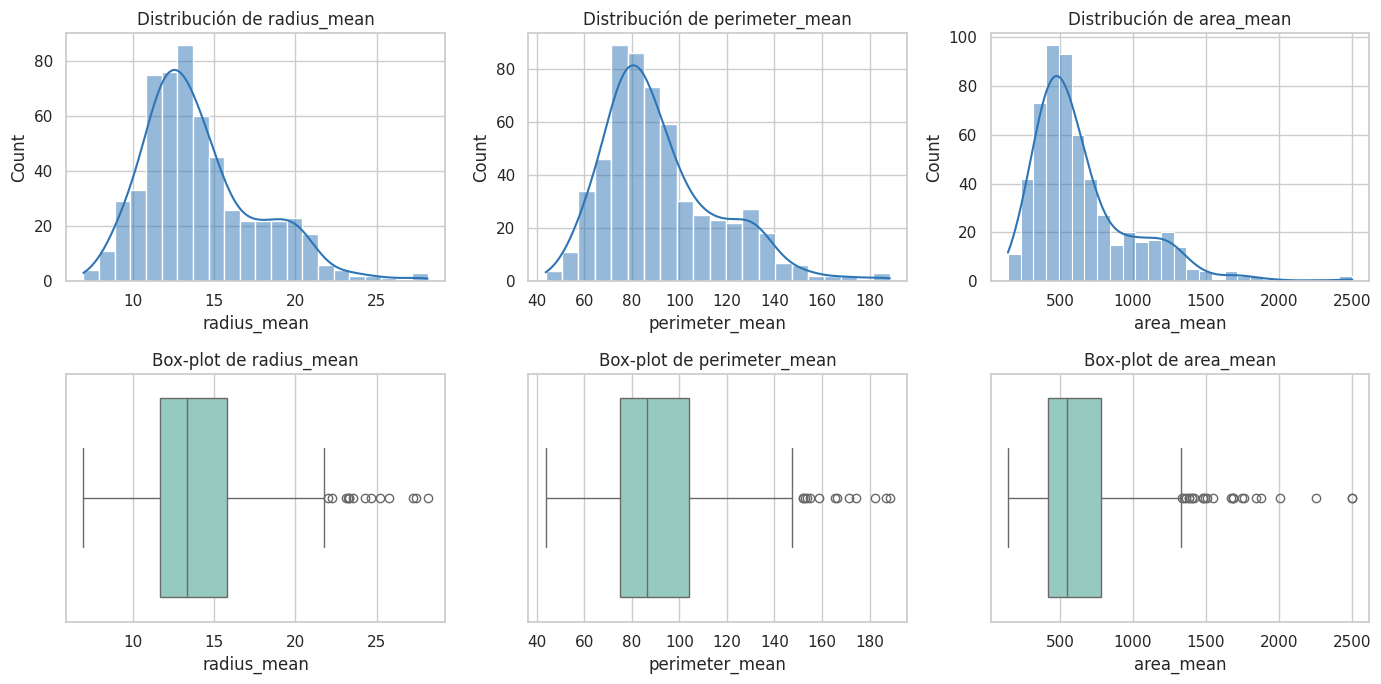

,radius_mean,perimeter_mean,area_mean
count,569.000000,569.000000,569.000000
mean,14.127292,91.969033,654.889104
std,3.524049,24.298981,351.914129
min,6.981000,43.790000,143.500000
25%,11.700000,75.170000,420.300000
50%,13.370000,86.240000,551.100000
75%,15.780000,104.100000,782.700000
max,28.110000,188.500000,2501.000000


In [8]:
vars_modelo = ["radius_mean", "perimeter_mean", "area_mean"]

fig, ejes = plt.subplots(2, 3, figsize=(14, 7))
for i, v in enumerate(vars_modelo):
    sns.histplot(bc[v], kde=True, ax=ejes[0, i], color="#2E75B6")
    ejes[0, i].set_title(f"Distribución de {v}")
    sns.boxplot(x=bc[v], ax=ejes[1, i], color="#8ED1C6")
    ejes[1, i].set_title(f"Box-plot de {v}")
plt.tight_layout()
plt.show()

bc[vars_modelo].describe()

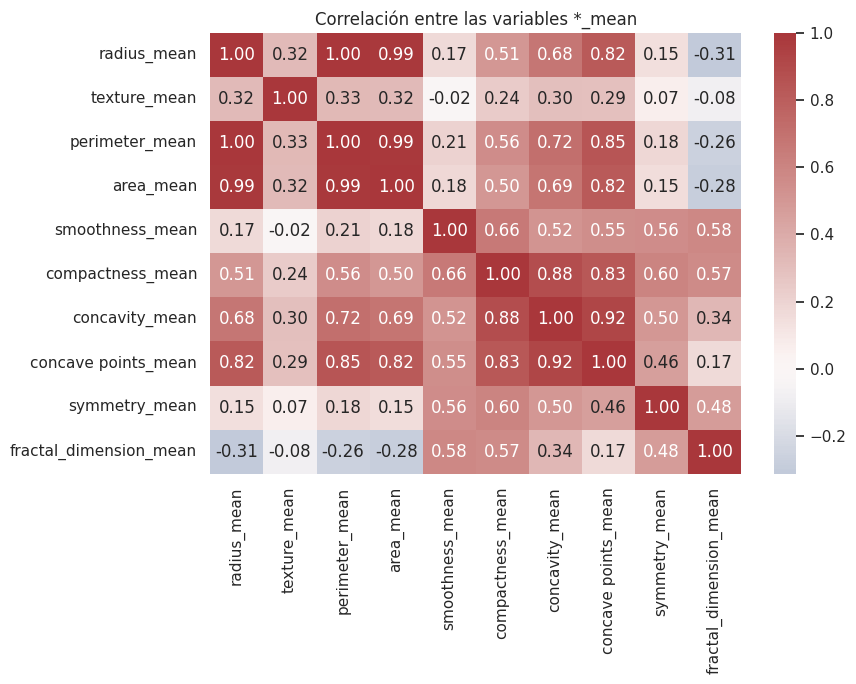

Correlaciones entre las variables del modelo:
                radius_mean  perimeter_mean  area_mean
radius_mean          1.0000          0.9979     0.9874
perimeter_mean       0.9979          1.0000     0.9865
area_mean            0.9874          0.9865     1.0000


In [9]:
cols_mean = [c for c in bc.columns if c.endswith("_mean")]

plt.figure(figsize=(9, 7))
sns.heatmap(bc[cols_mean].corr(), annot=True, fmt=".2f", cmap="vlag", center=0)
plt.title("Correlación entre las variables *_mean")
plt.tight_layout()
plt.show()

print("Correlaciones entre las variables del modelo:")
print(bc[vars_modelo].corr().round(4))

**Interpretación del EDA**

Las tres variables tienen una distribución asimétrica hacia la derecha: la mayoría de los núcleos son pequeños y hay una cola de núcleos grandes, que el box-plot marca como valores atípicos (más marcados en `area_mean`). En el gráfico de correlaciones, `radius_mean`, `perimeter_mean` y `area_mean` forman un bloque con correlaciones muy altas entre sí (**[0,998]** entre radio y perímetro y **[0,987]** entre radio y área). Esto tiene sentido geométrico: son tres formas de medir el tamaño del mismo núcleo. Por eso `radius_mean` es un buen candidato como predictor de las otras dos.

## 1.3 Modelos de regresión simple
Entreno dos modelos con `LinearRegression`, usando una partición 80/20 con `random_state=42`:
1. `perimeter_mean` (objetivo) ~ `radius_mean` (predictor)
2. `area_mean` (objetivo) ~ `radius_mean` (predictor)

In [10]:
def entrenar_regresion_simple(df, x_col, y_col, test_size=0.2, seed=42):
    X = df[[x_col]]
    y = df[y_col]
    X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=test_size, random_state=seed)

    modelo = LinearRegression()
    modelo.fit(X_tr, y_tr)

    pred_tr = modelo.predict(X_tr)
    pred_te = modelo.predict(X_te)

    metricas = {
        "objetivo (y)": y_col,
        "predictor (x)": x_col,
        "pendiente": modelo.coef_[0],
        "intercepto": modelo.intercept_,
        "R2_prueba": r2_score(y_te, pred_te),
        "MAE_prueba": mean_absolute_error(y_te, pred_te),
        "RMSE_prueba": np.sqrt(mean_squared_error(y_te, pred_te)),
        "R2_entrenamiento": r2_score(y_tr, pred_tr),
    }
    return modelo, (X_tr, X_te, y_tr, y_te), (pred_tr, pred_te), metricas

modelo_1, datos_1, preds_1, met_1 = entrenar_regresion_simple(bc, "radius_mean", "perimeter_mean")
print("MODELO 1: perimeter_mean ~ radius_mean")
for k, v in met_1.items():
    print(f"  {k}: {v:.4f}" if isinstance(v, float) else f"  {k}: {v}")

MODELO 1: perimeter_mean ~ radius_mean
  objetivo (y): perimeter_mean
  predictor (x): radius_mean
  pendiente: 6.8640
  intercepto: -5.0208
  R2_prueba: 0.9957
  MAE_prueba: 1.0424
  RMSE_prueba: 1.5834
  R2_entrenamiento: 0.9957


In [11]:
modelo_2, datos_2, preds_2, met_2 = entrenar_regresion_simple(bc, "radius_mean", "area_mean")
print("MODELO 2: area_mean ~ radius_mean")
for k, v in met_2.items():
    print(f"  {k}: {v:.4f}" if isinstance(v, float) else f"  {k}: {v}")

MODELO 2: area_mean ~ radius_mean
  objetivo (y): area_mean
  predictor (x): radius_mean
  pendiente: 99.0408
  intercepto: -743.8449
  R2_prueba: 0.9812
  MAE_prueba: 34.9748
  RMSE_prueba: 46.5776
  R2_entrenamiento: 0.9734


**Interpretación de la pendiente y el intercepto**

**Modelo 1 (`perimeter_mean ~ radius_mean`):** la pendiente es **[6,86]**: por cada unidad que aumenta el radio medio, el perímetro medio aumenta en promedio **[6,86]** unidades. El intercepto es **[-5,02]**: sería el perímetro predicho para un radio de cero, un valor sin sentido físico (un núcleo sin radio no existe ni tiene perímetro negativo), así que el intercepto solo ajusta la recta y no se interpreta literalmente.

**Modelo 2 (`area_mean ~ radius_mean`):** la pendiente es **[99,04]**: por cada unidad que aumenta el radio, el área aumenta en promedio **[99,04]** unidades. El intercepto es **[-743,84]**: el modelo predice un área negativa para radios pequeños, algo imposible, lo que ya sugiere que una recta no es la forma adecuada de relacionar radio y área.


## 1.4 Evaluación en el conjunto de prueba

In [12]:
tabla_bloque1 = pd.DataFrame([met_1, met_2]).set_index("objetivo (y)")
tabla_bloque1.round(4)

,predictor (x),pendiente,intercepto,R2_prueba,MAE_prueba,RMSE_prueba,R2_entrenamiento
objetivo (y),,,,,,,
perimeter_mean,radius_mean,6.8640,-5.0208,0.9957,1.0424,1.5834,0.9957
area_mean,radius_mean,99.0408,-743.8449,0.9812,34.9748,46.5776,0.9734


## 1.5 Visualización: regresión y residuos
Para cada modelo: a la izquierda la nube de puntos con su línea de regresión; a la derecha los residuos (real − predicho) contra los valores predichos.

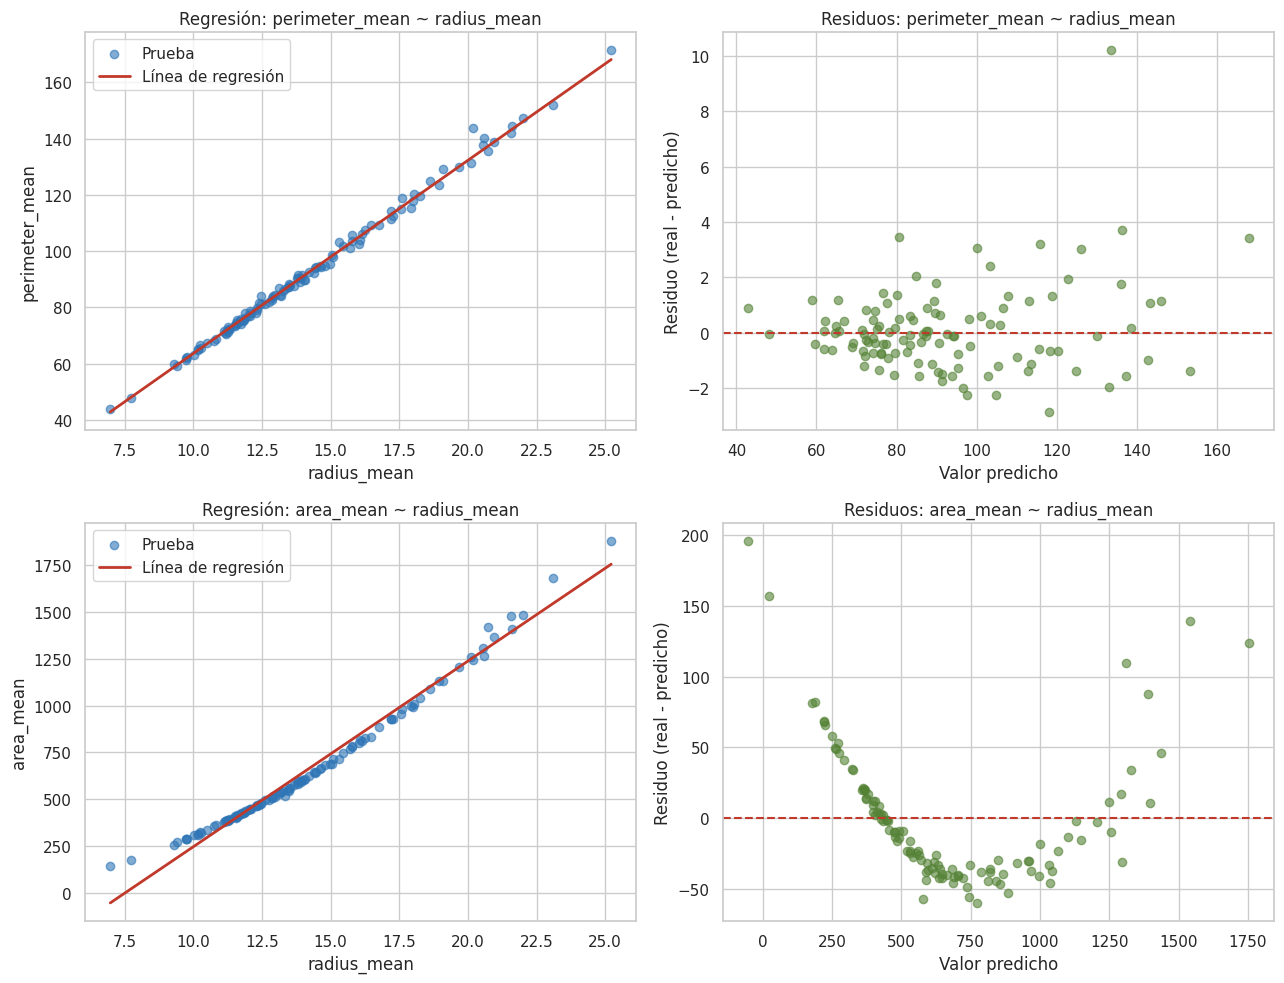

In [13]:
fig, ejes = plt.subplots(2, 2, figsize=(13, 10))

for fila, (nombre, modelo, datos, preds) in enumerate([
    ("perimeter_mean ~ radius_mean", modelo_1, datos_1, preds_1),
    ("area_mean ~ radius_mean", modelo_2, datos_2, preds_2),
]):
    X_tr, X_te, y_tr, y_te = datos
    pred_tr, pred_te = preds

    # Gráfico de la regresión: nube de puntos + línea de regresión
    ejes[fila, 0].scatter(X_te, y_te, alpha=0.6, label="Prueba", color="#2E75B6")
    orden = np.argsort(X_te.values.ravel())
    ejes[fila, 0].plot(X_te.values.ravel()[orden], pred_te[orden], color="#C0392B", lw=2, label="Línea de regresión")
    ejes[fila, 0].set_title(f"Regresión: {nombre}")
    ejes[fila, 0].set_xlabel("radius_mean")
    ejes[fila, 0].set_ylabel(nombre.split(" ~")[0])
    ejes[fila, 0].legend()

    # Gráfico de residuos: residuos vs valores predichos
    residuos = y_te - pred_te
    ejes[fila, 1].scatter(pred_te, residuos, alpha=0.6, color="#548235")
    ejes[fila, 1].axhline(0, color="#C0392B", ls="--")
    ejes[fila, 1].set_title(f"Residuos: {nombre}")
    ejes[fila, 1].set_xlabel("Valor predicho")
    ejes[fila, 1].set_ylabel("Residuo (real - predicho)")

plt.tight_layout()
plt.show()

**Comparación de métricas y gráficos**

| | Modelo 1 (perímetro) | Modelo 2 (área) |
|---|---|---|
| R² prueba | **[0,996]** | **[0,981]** |
| MAE prueba | **[1,04]** | **[34,97]** |
| RMSE prueba | **[1,58]** | **[46,58]** |

Los dos modelos tienen un R² altísimo, pero **las métricas de error no son comparables entre sí**, porque el perímetro y el área están en escalas distintas (el MAE de 34,97 del área no es "peor" que el 1,04 del perímetro; hay que verlo respecto de la magnitud de cada variable).

**Pregunta guía: ¿un R² alto es suficiente para concluir que una recta es el modelo adecuado?**

No. En el modelo 1 los residuos se reparten de forma aleatoria alrededor de cero, sin un patrón visible, lo que indica que la recta describe bien la relación. En el modelo 2, en cambio, los residuos forman una **curva en forma de U**: el modelo subestima el área en los radios pequeños y grandes y la sobrestima en los valores intermedios. Eso revela que la relación real no es lineal (es de tipo cuadrático, coherente con que el área de un círculo crece con el cuadrado del radio), y que la recta, pese a su R² de **[0,98]**, incumple el supuesto de linealidad. Además, ya vimos que el modelo predice áreas negativas para radios pequeños. Un R² alto dice que la recta se acerca a los puntos, pero **solo el gráfico de residuos muestra si el error es aleatorio o sistemático**.

---
# Bloque 2 · Regresión lineal múltiple con FIFA 19

El dataset *FIFA 19 complete player dataset* contiene más de 18.000 jugadores con atributos, valoración, valor de mercado y datos de contrato. La variable objetivo es **`Overall`**, la valoración general del jugador.

## 2.0 Carga de datos

In [14]:
import kagglehub

path_fifa = kagglehub.dataset_download("chaitanyahivlekar/fifa-19-player-dataset")
print("Archivos descargados en:", path_fifa)
print(os.listdir(path_fifa))

100%|██████████| 1.68M/1.68M [00:00<00:00, 89.5MB/s]

Extracting files...
Archivos descargados en: /root/.cache/kagglehub/datasets/chaitanyahivlekar/fifa-19-player-dataset/versions/1
['FIFA19.csv']


In [15]:
csvs_fifa = glob.glob(os.path.join(path_fifa, "**", "*.csv"), recursive=True)
fifa = None
for a in csvs_fifa:
    cols = pd.read_csv(a, nrows=0).columns.tolist()
    print(os.path.basename(a), "->", len(cols), "columnas")
    if fifa is None and "Overall" in cols:
        archivo_fifa = a
        fifa = pd.read_csv(a)

assert fifa is not None, "No se encontró un CSV con la columna Overall"
print("\nArchivo principal:", os.path.basename(archivo_fifa))
print("Dimensiones:", fifa.shape)
fifa.head()

FIFA19.csv -> 58 columnas

Archivo principal: FIFA19.csv
Dimensiones: (18147, 58)


,Unnamed: 0,Name,Age,Nationality,Overall,Potential,Club,Value,Wage,Preferred Foot,International Reputation,Weak Foot,Skill Moves,Work Rate,Position,Jersey Number,Joined,Loaned From,Contract Valid Until,Height,Weight,Crossing,Finishing,HeadingAccuracy,ShortPassing,...,Agility,Reactions,Balance,ShotPower,Jumping,Stamina,Strength,LongShots,Aggression,Interceptions,Positioning,Vision,Penalties,Composure,Marking,StandingTackle,SlidingTackle,GKDiving,GKHandling,GKKicking,GKPositioning,GKReflexes,Release Clause,League,Speciality
0,0,L. Messi,31,Argentina,94,94,FC Barcelona,€110.5M,€565K,Left,5.0,4.0,4.0,Medium/ Medium,RF,10.0,"Jul 1, 2004",Not on loan,2021,5'7,159lbs,84.0,95.0,70.0,90.0,...,91.0,95.0,95.0,85.0,68.0,72.0,59.0,94.0,48.0,22.0,94.0,94.0,75.0,96.0,33.0,28.0,26.0,6.0,11.0,15.0,14.0,8.0,€226.5M,LALIGA SANTANDER,Complete Forward
1,1,Cristiano Ronaldo,33,Portugal,94,94,Juventus,€77M,€405K,Right,5.0,4.0,5.0,High/ Low,ST,7.0,"Jul 10, 2018",Not on loan,2022,6'2,183lbs,84.0,94.0,89.0,81.0,...,87.0,96.0,70.0,95.0,95.0,88.0,79.0,93.0,63.0,29.0,95.0,82.0,85.0,95.0,28.0,31.0,23.0,7.0,11.0,15.0,14.0,11.0,€127.1M,SERIE A TIM,Distance Shooter
2,2,Neymar Jr,26,Brazil,92,93,Paris Saint-Germain,€118.5M,€290K,Right,5.0,5.0,5.0,High/ Medium,LW,10.0,"Aug 3, 2017",Not on loan,2022,5'9,150lbs,79.0,87.0,62.0,84.0,...,96.0,94.0,84.0,80.0,61.0,81.0,49.0,82.0,56.0,36.0,89.0,87.0,81.0,94.0,27.0,24.0,33.0,9.0,9.0,15.0,15.0,11.0,€228.1M,LIGUE 1 CONFORAMA,Complete Forward
3,3,De Gea,27,Spain,91,93,Manchester United,€72M,€260K,Right,4.0,3.0,1.0,Medium/ Medium,GK,1.0,"Jul 1, 2011",Not on loan,2020,6'4,168lbs,17.0,13.0,21.0,50.0,...,60.0,90.0,43.0,31.0,67.0,43.0,64.0,12.0,38.0,30.0,12.0,68.0,40.0,68.0,15.0,21.0,13.0,90.0,85.0,87.0,88.0,94.0,€138.6M,PREMIER LEAGUE,Goalkeeper
4,4,K. De Bruyne,27,Belgium,91,92,Manchester City,€102M,€355K,Right,4.0,5.0,4.0,High/ High,RCM,7.0,"Aug 30, 2015",Not on loan,2023,5'11,154lbs,93.0,82.0,55.0,92.0,...,79.0,91.0,77.0,91.0,63.0,90.0,75.0,91.0,76.0,61.0,87.0,94.0,79.0,88.0,68.0,58.0,51.0,15.0,13.0,5.0,10.0,13.0,€196.4M,PREMIER LEAGUE,Complete Midfielder


In [16]:
print("Tipos de dato:")
print(fifa.dtypes.value_counts())

nulos_fifa = fifa.isnull().sum()
print("\nColumnas con más nulos:")
print(nulos_fifa[nulos_fifa > 0].sort_values(ascending=False).head(10))
print("\nNulos en la variable objetivo (Overall):", fifa["Overall"].isnull().sum())

Tipos de dato:
float64    38
object     16
int64       4
Name: count, dtype: int64

Columnas con más nulos:
Joined    1493
dtype: int64

Nulos en la variable objetivo (Overall): 0


## 2.1 EDA del ejercicio

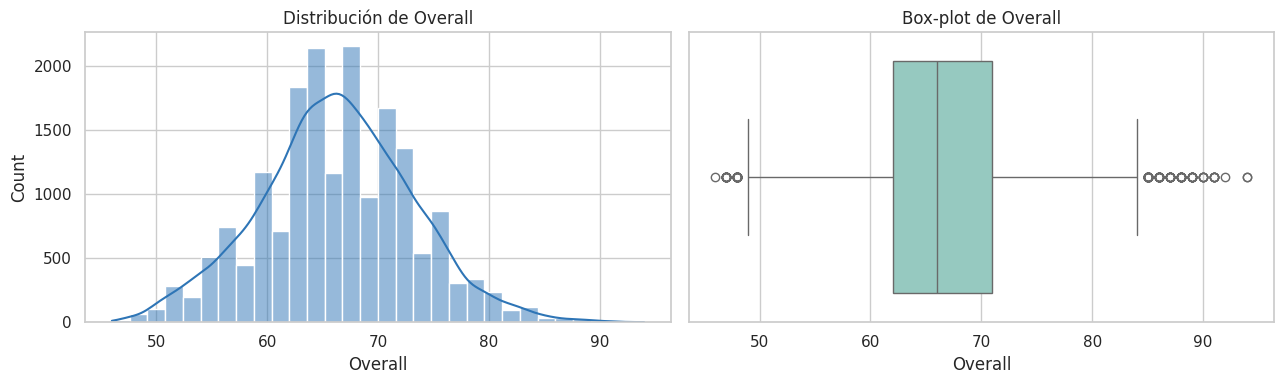

,Overall
count,18147.000000
mean,66.253926
std,6.913320
min,46.000000
25%,62.000000
50%,66.000000
75%,71.000000
max,94.000000


In [17]:
fig, ejes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(fifa["Overall"], bins=30, kde=True, ax=ejes[0], color="#2E75B6")
ejes[0].set_title("Distribución de Overall")
sns.boxplot(x=fifa["Overall"], ax=ejes[1], color="#8ED1C6")
ejes[1].set_title("Box-plot de Overall")
plt.tight_layout()
plt.show()

fifa["Overall"].describe()

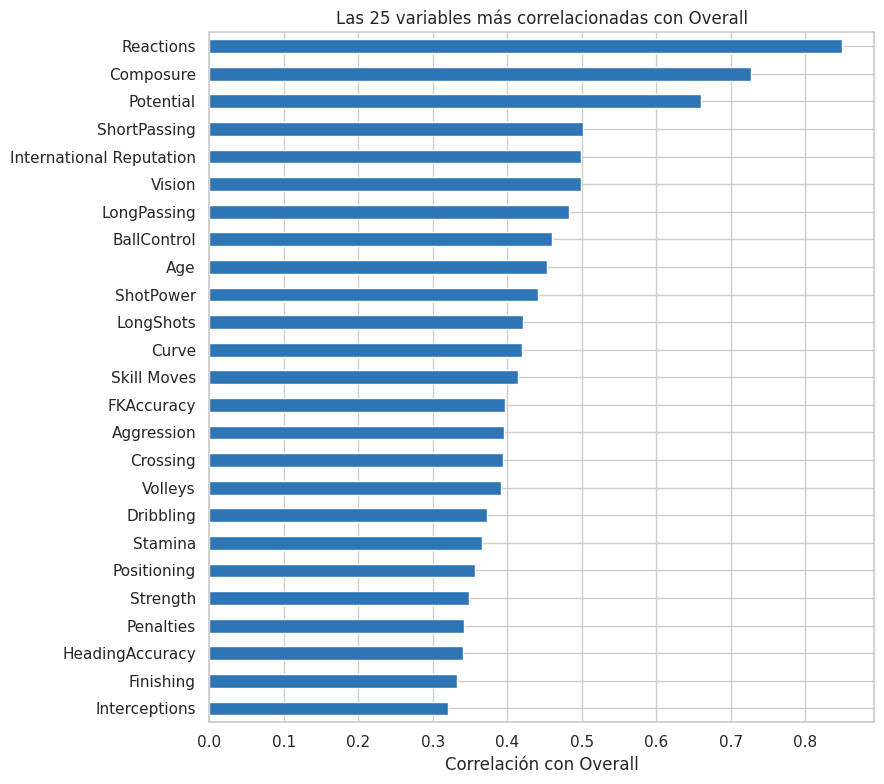

,Overall
Reactions,0.850
Composure,0.728
Potential,0.661
ShortPassing,0.502
International Reputation,0.500
Vision,0.499
LongPassing,0.484
BallControl,0.460
Age,0.453
ShotPower,0.441


In [18]:
ids = [c for c in ["Unnamed: 0", "ID", "Jersey Number"] if c in fifa.columns]
numericas = fifa.select_dtypes(include=np.number).drop(columns=ids)

corr_overall = numericas.corr()["Overall"].drop("Overall").sort_values(key=abs, ascending=False)

plt.figure(figsize=(9, 8))
corr_overall.head(25).sort_values().plot(kind="barh", color="#2E75B6")
plt.title("Las 25 variables más correlacionadas con Overall")
plt.xlabel("Correlación con Overall")
plt.tight_layout()
plt.show()

corr_overall.head(25).round(3)

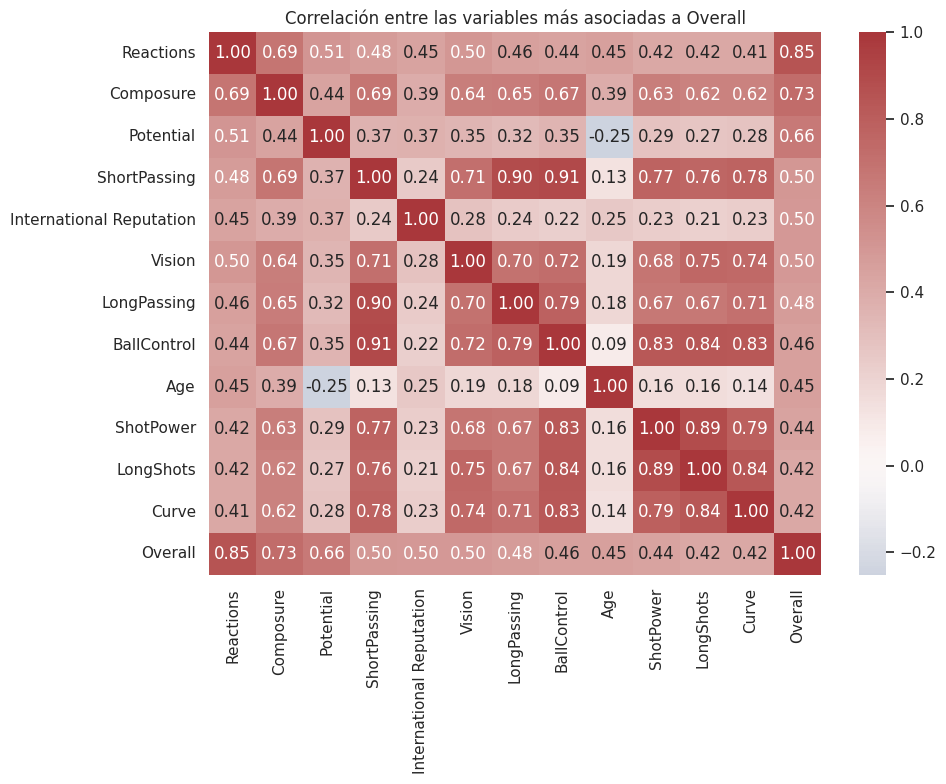

In [19]:
top = corr_overall.head(12).index.tolist() + ["Overall"]

plt.figure(figsize=(10, 8))
sns.heatmap(numericas[top].corr(), annot=True, fmt=".2f", cmap="vlag", center=0)
plt.title("Correlación entre las variables más asociadas a Overall")
plt.tight_layout()
plt.show()

**Interpretación del EDA**

`Overall` tiene una distribución **casi simétrica, en forma de campana**, centrada en torno a los 66 puntos (media 66,3, mediana 66 y desviación estándar 6,9), con valores entre **46 y 94**. El box-plot muestra valores atípicos en ambos extremos, **más numerosos en el extremo alto** (entre 85 y 94 puntos), que corresponden a los jugadores de élite. Los predictores no tienen nulos: se conservaron las 18.147 filas (la única columna con nulos es `Joined`, con 1.493, que no uso).

En el gráfico de correlaciones, las variables más asociadas a `Overall` son **`Reactions` (r = 0,85)**, **`Composure` (0,73)** y **`Potential` (0,66)**, seguidas de `ShortPassing`, `International Reputation` y `Vision` (todas cerca de 0,50). Hay un punto que hay que mirar con cuidado: algunas de las variables más correlacionadas **no necesariamente son buenos predictores**, porque pueden contener la respuesta. Es el caso de **`Potential`** (se calcula a partir de la misma valoración) y, en menor medida, de `International Reputation`. `Value` y `Wage` no aparecen en el gráfico porque vienen como texto, pero también son consecuencias de `Overall`. Eso lo reviso en la sección siguiente con la pregunta de control de data leakage.

## 2.2 Selección de predictores y data leakage

**Pregunta de control** que apliqué a cada variable: ¿existiría antes de conocer el valor de `Overall`? ¿Se calcula a partir de él, o ambos provienen de una misma fuente?

**Variables que descarto (y por qué):**

| Variable | Motivo |
|---|---|
| `Potential` | Es una estimación de cuánto podría llegar a valer `Overall`; viene de la misma valoración y, para muchos jugadores, es igual o muy cercana a ella. |
| `Value`, `Wage`, `Release Clause` | Son **consecuencias** de `Overall`: el valor de mercado y el sueldo dependen de la valoración, así que no existirían antes de conocerla. Además vienen como texto (€, M, K). |
| `Unnamed: 0`, `Jersey Number` | Un índice y un número de camiseta, sin relación con la habilidad. |

**Variables que mantengo como candidatas:** `Age` y los atributos de habilidad (`Reactions`, `Composure`, `ShortPassing`, `BallControl`, `Dribbling`, `Vision`, `Stamina`, `Strength`, `Aggression`). Son mediciones de habilidades que existen antes de resumir al jugador en una sola nota.

**Variable discutible:** `International Reputation`. La descarto: es una nota de 1 a 5 que el juego asigna según la fama del jugador, y la fama depende de su calidad, así que parece más una **consecuencia** de la valoración que una causa (los jugadores con mayor `Overall` suelen ser los más famosos). Incluirla filtraría parte de la respuesta.

**Limitación honesta:** `Overall` se construye en el juego con una fórmula sobre estos atributos. Por eso mi modelo, en parte, está "reconstruyendo" esa fórmula, y su buen desempeño no demuestra que sirva para valorar jugadores de la vida real.

In [20]:
candidatos = ["Age", "Reactions", "Composure", "ShortPassing", "BallControl",
              "Dribbling", "Vision", "Stamina", "Strength", "Aggression"]

# Si algún nombre no existe en tu CSV, se avisa aquí
faltan = [c for c in candidatos if c not in fifa.columns]
print("Candidatas que NO existen en el dataset:", faltan)
candidatos = [c for c in candidatos if c in fifa.columns]

print(f"\nCandidatas ({len(candidatos)}) y su correlación con Overall:")
print(fifa[candidatos + ["Overall"]].corr()["Overall"].drop("Overall").round(3).sort_values(ascending=False))

Candidatas que NO existen en el dataset: []

Candidatas (10) y su correlación con Overall:
Reactions       0.850
Composure       0.728
ShortPassing    0.502
Vision          0.499
BallControl     0.460
Age             0.453
Aggression      0.395
Dribbling       0.372
Stamina         0.366
Strength        0.349
Name: Overall, dtype: float64


In [21]:
# Registro de las variables que NO uso
descartadas = {
    "Potential": "se calcula a partir de la misma valoración; para muchos jugadores es igual o muy cercana a Overall",
    "Value": "consecuencia de Overall (el valor de mercado depende de la valoración)",
    "Wage": "consecuencia de Overall",
    "Release Clause": "consecuencia de Overall",
    "Unnamed: 0, Jersey Number": "índice y número de camiseta, sin relación con la habilidad",
}
pd.DataFrame(descartadas.items(), columns=["variable", "motivo"])

,variable,motivo
0,Potential,se calcula a partir de la misma valoración; pa...
1,Value,consecuencia de Overall (el valor de mercado d...
2,Wage,consecuencia de Overall
3,Release Clause,consecuencia de Overall
4,"Unnamed: 0, Jersey Number","índice y número de camiseta, sin relación con ..."


## 2.3 Multicolinealidad
Cuando varios predictores aportan información parecida, el modelo puede predecir bien pero **sus coeficientes se vuelven inestables y difíciles de interpretar**. La reviso con la matriz de correlación entre predictores y con el **VIF** (factor de inflación de la varianza); como regla práctica, un VIF sobre 5–10 es una señal de alerta.

Filas antes: 18147 | filas tras eliminar nulos: 18147


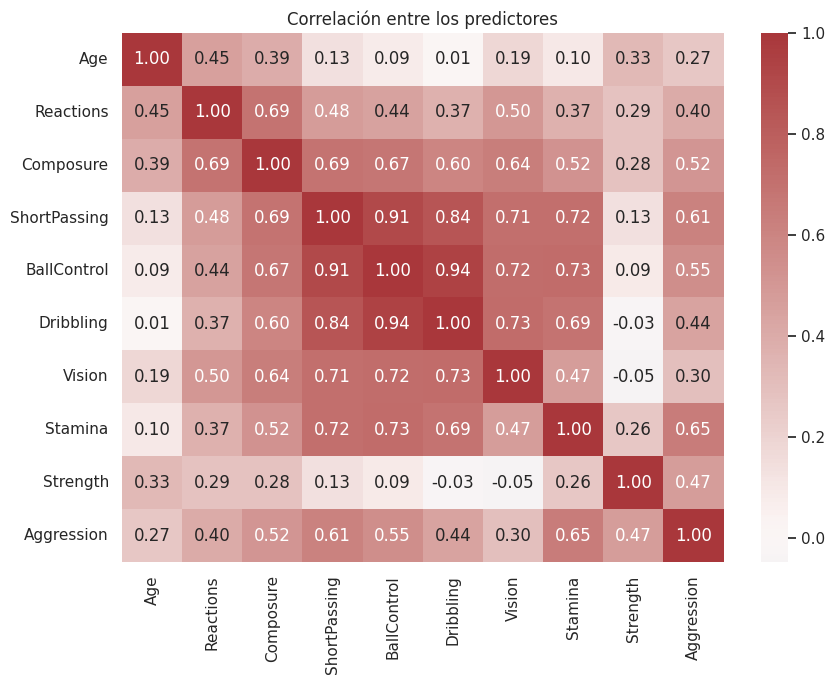

,variable,VIF
0,BallControl,15.77
1,Dribbling,10.68
2,ShortPassing,7.30
3,Composure,3.19
4,Vision,2.95
5,Stamina,2.76
6,Aggression,2.52
7,Reactions,2.14
8,Strength,1.63
9,Age,1.47


In [22]:
datos2 = fifa[candidatos + ["Overall", "Position"]].dropna()
print("Filas antes:", len(fifa), "| filas tras eliminar nulos:", len(datos2))

# Matriz de correlación entre predictores
plt.figure(figsize=(9, 7))
sns.heatmap(datos2[candidatos].corr(), annot=True, fmt=".2f", cmap="vlag", center=0)
plt.title("Correlación entre los predictores")
plt.tight_layout()
plt.show()

def calcular_vif(X):
    Xc = sm.add_constant(X)
    vif = pd.DataFrame({
        "variable": X.columns,
        "VIF": [variance_inflation_factor(Xc.values, i + 1) for i in range(len(X.columns))],
    })
    return vif.sort_values("VIF", ascending=False).reset_index(drop=True)

vif_inicial = calcular_vif(datos2[candidatos])
vif_inicial.round(2)

In [23]:
# ✍️ Decide qué variables eliminar según el VIF y tu criterio (regla práctica: VIF > 5-10 = alerta)
a_eliminar = []    # ejemplo: ["Dribbling"]  (déjala vacía si decides mantener todas)

predictores_finales = [c for c in candidatos if c not in a_eliminar]
print("Predictores finales:", predictores_finales)

calcular_vif(datos2[predictores_finales]).round(2)

Predictores finales: ['Age', 'Reactions', 'Composure', 'ShortPassing', 'BallControl', 'Dribbling', 'Vision', 'Stamina', 'Strength', 'Aggression']


,variable,VIF
0,BallControl,15.77
1,Dribbling,10.68
2,ShortPassing,7.30
3,Composure,3.19
4,Vision,2.95
5,Stamina,2.76
6,Aggression,2.52
7,Reactions,2.14
8,Strength,1.63
9,Age,1.47


**Decisión sobre multicolinealidad**

En la matriz de correlación entre predictores, los pares más correlacionados son **`BallControl` y `Dribbling` (r = 0,94)** y **`ShortPassing` y `BallControl` (r = 0,91)**, seguidos de `ShortPassing` y `Dribbling` (0,84). Esto tiene sentido porque son habilidades técnicas con el balón: un jugador que controla bien el balón suele también regatear y pasar bien. El VIF más alto fue **`BallControl` con 15,77**, seguido de `Dribbling` (10,68) y `ShortPassing` (7,30): **3 variables superaron un VIF de 5**, y dos superaron 10.

**Decisión:** mantuve todas las variables, porque el objetivo de este bloque es predecir `Overall` y la multicolinealidad no daña la capacidad predictiva (más abajo el R² de prueba es casi igual al de entrenamiento), y eliminar habilidades técnicas dejaría fuera información. Como no eliminé ninguna, el VIF máximo sigue en 15,77. **Por eso los coeficientes individuales de `BallControl`, `Dribbling` y `ShortPassing` deben interpretarse con cautela:** pueden cambiar de valor o incluso de signo al agregar o quitar variables parecidas (más abajo se ve un ejemplo con `Dribbling`).

## 2.4 Modelo de regresión múltiple
Partición 80/20 con `random_state=42`; se reportan R², MAE y RMSE (en puntos de `Overall`) en ambos conjuntos.

In [24]:
X = datos2[predictores_finales]
y = datos2["Overall"]
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=42)

modelo_fifa = LinearRegression().fit(X_tr, y_tr)
pred_tr = modelo_fifa.predict(X_tr)
pred_te = modelo_fifa.predict(X_te)

def metricas(y_real, y_pred):
    return {
        "R2": r2_score(y_real, y_pred),
        "MAE": mean_absolute_error(y_real, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_real, y_pred)),
    }

tabla_metricas = pd.DataFrame({
    "Entrenamiento": metricas(y_tr, pred_tr),
    "Prueba": metricas(y_te, pred_te),
}).T
print("Métricas del modelo múltiple (Overall en puntos):")
tabla_metricas.round(4)

Métricas del modelo múltiple (Overall en puntos):


,R2,MAE,RMSE
Entrenamiento,0.7780,2.5739,3.2674
Prueba,0.7732,2.5567,3.2519


In [25]:
coefs = pd.DataFrame({
    "predictor": predictores_finales,
    "coeficiente": modelo_fifa.coef_,
}).sort_values("coeficiente", key=abs, ascending=False)
coefs["unidad"] = "puntos de Overall por cada punto del predictor (resto constante)"

print(f"Intercepto: {modelo_fifa.intercept_:.3f}")
coefs.round(4)

Intercepto: 22.015


,predictor,coeficiente,unidad
1,Reactions,0.4803,puntos de Overall por cada punto del predictor...
2,Composure,0.1509,puntos de Overall por cada punto del predictor...
8,Strength,0.0674,puntos de Overall por cada punto del predictor...
0,Age,0.0499,puntos de Overall por cada punto del predictor...
3,ShortPassing,0.0418,puntos de Overall por cada punto del predictor...
5,Dribbling,-0.0373,puntos de Overall por cada punto del predictor...
9,Aggression,-0.0341,puntos de Overall por cada punto del predictor...
4,BallControl,0.0224,puntos de Overall por cada punto del predictor...
6,Vision,0.0182,puntos de Overall por cada punto del predictor...
7,Stamina,-0.0114,puntos de Overall por cada punto del predictor...


Predictor más correlacionado: Reactions


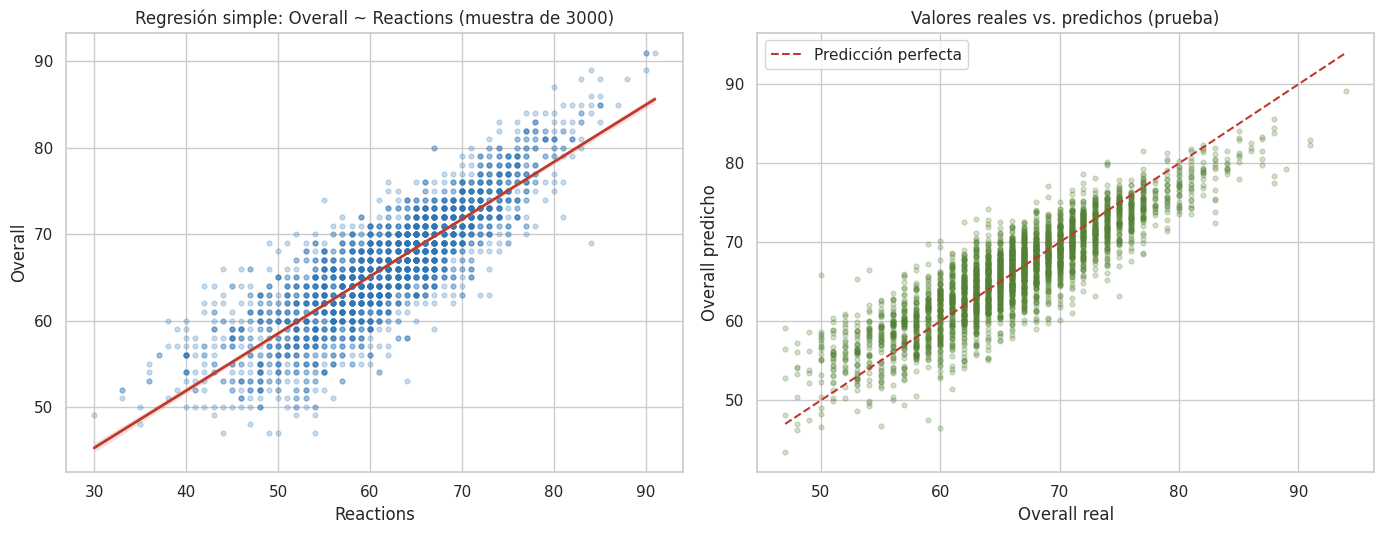

In [26]:
# Predictor más correlacionado con Overall dentro de los finales
mejor = datos2[predictores_finales + ["Overall"]].corr()["Overall"].drop("Overall").abs().idxmax()
print("Predictor más correlacionado:", mejor)

fig, ejes = plt.subplots(1, 2, figsize=(14, 5.5))

muestra = datos2.sample(min(3000, len(datos2)), random_state=1)
sns.regplot(data=muestra, x=mejor, y="Overall", ax=ejes[0],
            scatter_kws={"alpha": 0.25, "s": 12, "color": "#2E75B6"}, line_kws={"color": "#C0392B", "lw": 2})
ejes[0].set_title(f"Regresión simple: Overall ~ {mejor} (muestra de 3000)")

ejes[1].scatter(y_te, pred_te, alpha=0.25, s=12, color="#548235")
lim = [y_te.min(), y_te.max()]
ejes[1].plot(lim, lim, color="#C0392B", ls="--", label="Predicción perfecta")
ejes[1].set_xlabel("Overall real")
ejes[1].set_ylabel("Overall predicho")
ejes[1].set_title("Valores reales vs. predichos (prueba)")
ejes[1].legend()
plt.tight_layout()
plt.show()

**Interpretación de métricas y coeficientes**

**Métricas:** en el conjunto de prueba el modelo obtuvo R² = **0,773**, MAE = **2,56** puntos y RMSE = **3,25** puntos. En entrenamiento fueron R² = 0,778, MAE = 2,57 y RMSE = 3,27. La diferencia entre ambos conjuntos es **mínima**, lo que indica que **no hay sobreajuste**: con 18.000 jugadores y solo 10 predictores el modelo generaliza bien. Un MAE de 2,56 significa que, en promedio, el modelo se equivoca en unos **2,6 puntos de valoración**, frente a una desviación estándar de `Overall` de 6,9.

**Tres coeficientes interpretados (con unidades):**

1. **`Reactions` = 0,480:** manteniendo constantes las demás variables, un punto más en `Reactions` se asocia con **0,48 puntos más** de `Overall`. Es el coeficiente más grande, coherente con que sea la variable más correlacionada (r = 0,85).
2. **`Composure` = 0,151:** un punto más en `Composure` se asocia con **0,15 puntos más** de `Overall`.
3. **`Dribbling` = −0,037:** un punto más en `Dribbling` se asocia con **0,04 puntos menos** de `Overall`, manteniendo constantes las demás variables. Este signo sorprende, porque `Dribbling` está positivamente correlacionado con `Overall` (r = 0,37). Se explica por la multicolinealidad: `Dribbling` está casi duplicado por `BallControl` (r = 0,94), así que su coeficiente mide el efecto *una vez descontadas* las variables que se le parecen, no su efecto solo. Es justo la inestabilidad que advertía el VIF de 10,7.

El intercepto (22,0) es el valor predicho si todos los predictores valieran cero, algo que no ocurre en la práctica, así que no se interpreta literalmente.

**Gráficos:** en la regresión simple de `Reactions` contra `Overall` se ve una tendencia lineal creciente clara, con dispersión moderada. En el gráfico de reales contra predichos, los puntos siguen la diagonal, pero el modelo **comprime los extremos**: tiende a sobrestimar a los jugadores con `Overall` bajo (menos de 55) y a subestimar a los de `Overall` alto (más de 80).

## 2.5 Heterogeneidad
Un error promedio puede esconder que el modelo falla de forma sistemática en un grupo. Defino cuatro subgrupos según la posición (portero, defensa, mediocampo y delantero) y calculo las métricas en cada uno.

In [27]:
# Subgrupos de jugadores a partir de la columna Position
def grupo_posicion(p):
    if p == "GK":
        return "Portero"
    if p in ["CB", "LCB", "RCB", "LB", "RB", "LWB", "RWB"]:
        return "Defensa"
    if p in ["CDM", "LDM", "RDM", "CM", "LCM", "RCM", "CAM", "LAM", "RAM", "LM", "RM"]:
        return "Mediocampo"
    return "Delantero"

datos2["Grupo"] = datos2["Position"].apply(grupo_posicion)
grupo_te = datos2.loc[X_te.index, "Grupo"]

filas = []
for g in ["Portero", "Defensa", "Mediocampo", "Delantero"]:
    m = grupo_te == g
    r = metricas(y_te[m], pred_te[m])
    filas.append({"grupo": g, "n_prueba": int(m.sum()), **r,
                  "sesgo_medio": float((y_te[m] - pred_te[m]).mean())})

tabla_grupos = pd.DataFrame(filas).set_index("grupo")
print("Métricas por subgrupo (conjunto de prueba):")
tabla_grupos.round(3)

Métricas por subgrupo (conjunto de prueba):


,n_prueba,R2,MAE,RMSE,sesgo_medio
grupo,,,,,
Portero,407,0.717,3.276,4.079,1.478
Defensa,1157,0.802,2.255,2.844,0.400
Mediocampo,1386,0.753,2.643,3.343,-0.509
Delantero,680,0.802,2.465,3.154,-0.594


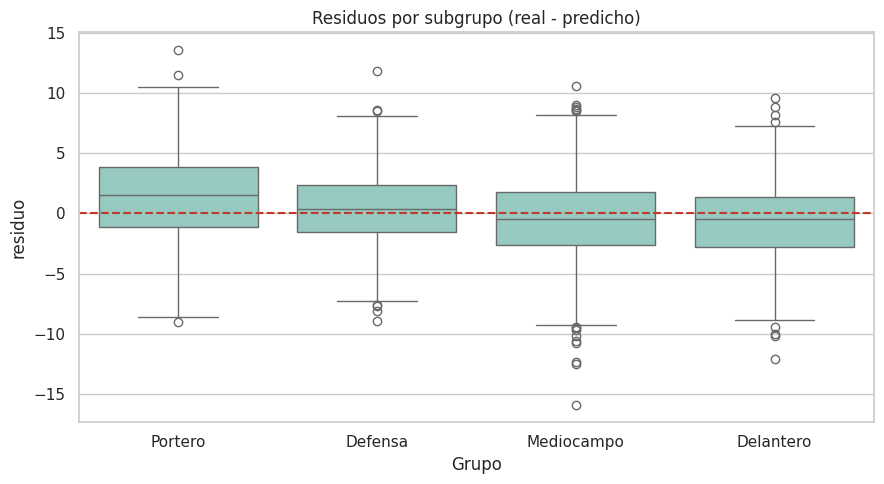

In [28]:
residuos_te = (y_te - pred_te).to_frame("residuo")
residuos_te["Grupo"] = grupo_te

plt.figure(figsize=(9, 5))
sns.boxplot(data=residuos_te, x="Grupo", y="residuo", order=["Portero", "Defensa", "Mediocampo", "Delantero"], color="#8ED1C6")
plt.axhline(0, color="#C0392B", ls="--")
plt.title("Residuos por subgrupo (real - predicho)")
plt.tight_layout()
plt.show()

**Comparación entre subgrupos**

El modelo global tiene un MAE de 2,56, pero por subgrupo varía así: portero **3,28**, defensa **2,26**, mediocampo **2,64** y delantero **2,47**. El grupo donde peor funciona es **el de los porteros**, con el R² más bajo (**0,717**, frente a 0,80 en defensas y delanteros) y un sesgo medio de **+1,48 puntos**: el modelo **subestima** su valoración, algo que también se ve en el box-plot de residuos, centrado por encima de cero. En mediocampo y delantero ocurre lo contrario, con una ligera sobrestimación (−0,51 y −0,59).

**Posible explicación:** la valoración de un portero depende sobre todo de atributos propios de su puesto (`GKDiving`, `GKReflexes`, etc.), que no están entre mis predictores; mis variables solo capturan una parte de lo que los define. Esto muestra que **una sola recta global no describe igual de bien a todos los grupos**, y que el error promedio oculta ese problema. Aun así, las diferencias son moderadas (el MAE va de 2,3 a 3,3 puntos). Una posible mejora sería **ajustar un modelo aparte para porteros o incluir los atributos específicos del puesto**.

## 2.6 Desafío opcional: predecir `Value`
La columna `Value` viene como texto (por ejemplo `€110.5M` o `€565K`). La convierto a número, miro su distribución y pruebo si una transformación logarítmica mejora el modelo.

count    1.814700e+04
mean     2.417729e+06
std      5.602826e+06
min      0.000000e+00
25%      3.000000e+05
50%      6.750000e+05
75%      2.000000e+06
max      1.185000e+08
Name: Value_num, dtype: float64


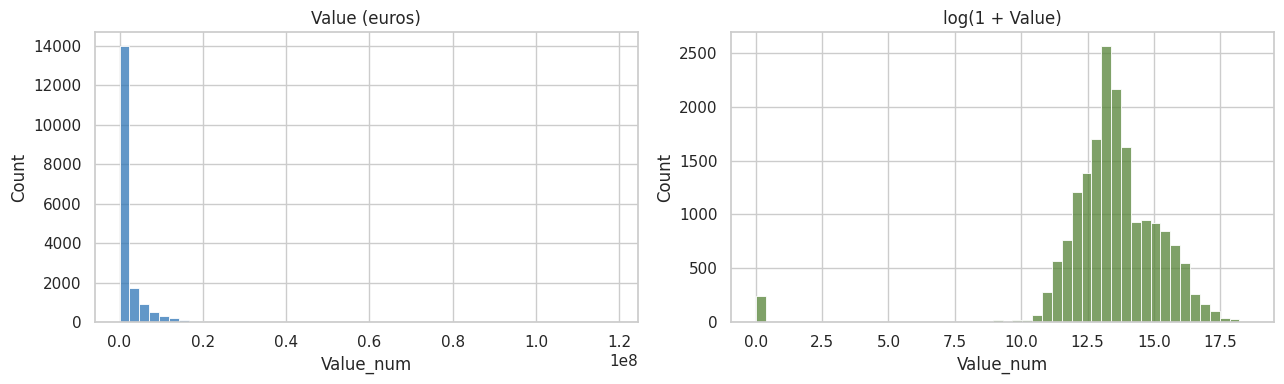

In [29]:
def a_numero(txt):
    """Convierte textos como '€110.5M' o '€565K' en números."""
    if pd.isna(txt):
        return np.nan
    t = str(txt).replace("€", "").strip()
    mult = 1
    if t.endswith("M"):
        mult, t = 1e6, t[:-1]
    elif t.endswith("K"):
        mult, t = 1e3, t[:-1]
    try:
        return float(t) * mult
    except ValueError:
        return np.nan

fifa["Value_num"] = fifa["Value"].apply(a_numero)
print(fifa["Value_num"].describe())

fig, ejes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(fifa["Value_num"].dropna(), bins=50, ax=ejes[0], color="#2E75B6")
ejes[0].set_title("Value (euros)")
sns.histplot(np.log1p(fifa["Value_num"].dropna()), bins=50, ax=ejes[1], color="#548235")
ejes[1].set_title("log(1 + Value)")
plt.tight_layout()
plt.show()

In [30]:
datos_v = fifa[predictores_finales + ["Value_num"]].dropna()
Xv = datos_v[predictores_finales]
Xv_tr, Xv_te, yv_tr, yv_te = train_test_split(Xv, datos_v["Value_num"], test_size=0.2, random_state=42)

# Modelo sin transformar
m_raw = LinearRegression().fit(Xv_tr, yv_tr)
r2_raw = r2_score(yv_te, m_raw.predict(Xv_te))

# Modelo con log1p(Value): se evalúa en escala log y también devuelto a euros
m_log = LinearRegression().fit(Xv_tr, np.log1p(yv_tr))
pred_log = m_log.predict(Xv_te)
r2_log = r2_score(np.log1p(yv_te), pred_log)
r2_log_euros = r2_score(yv_te, np.expm1(pred_log))

print(f"Value sin transformar         -> R² prueba (euros): {r2_raw:.3f}")
print(f"log(1+Value)                  -> R² prueba (escala log): {r2_log:.3f}")
print(f"log(1+Value) devuelto a euros -> R² prueba (euros): {r2_log_euros:.3f}")

Value sin transformar         -> R² prueba (euros): 0.341
log(1+Value)                  -> R² prueba (escala log): 0.336
log(1+Value) devuelto a euros -> R² prueba (euros): 0.585


---
# Bloque 3 · Transferencia a mi propio dataset: Student Performance

Aplico el flujo completo del laboratorio (EDA, selección de predictores, multicolinealidad, partición, métricas, residuos y heterogeneidad) a mi dataset del Laboratorio 01, *Student Performance & Study Habits* (Harshada Patil, Kaggle, CC0): 1000 estudiantes con hábitos de estudio, estilo de vida, demografía y notas.

## 3.0 Carga de datos

In [31]:
try:
    path_est = kagglehub.dataset_download("harshadapatil31/student-performance-and-study-habits-dataset")
    csv_est = glob.glob(os.path.join(path_est, "**", "*.csv"), recursive=True)[0]
    print("Descargado con kagglehub:", csv_est)
except Exception as e:
    print("kagglehub no pudo descargarlo (", type(e).__name__, "). Subo el CSV manualmente.")
    from google.colab import files
    csv_est = next(iter(files.upload()))

est = pd.read_csv(csv_est)
print("Dimensiones:", est.shape)
est.head()

100%|██████████| 14.7k/14.7k [00:00<00:00, 21.5MB/s]

Extracting files...
Descargado con kagglehub: /root/.cache/kagglehub/datasets/harshadapatil31/student-performance-and-study-habits-dataset/versions/1/student_performance_dataset.csv
Dimensiones: (1000, 12)


,student_id,gender,study_time_hours,attendance_percent,sleep_hours,parental_education,internet_access,extracurricular_activities,part_time_job,previous_grade,final_exam_score,final_grade
0,1,Male,4.0,98.0,6.5,Bachelors,Yes,Yes,No,76.9,100.0,A
1,2,Female,6.3,100.0,5.7,High School,Yes,Yes,Yes,75.5,100.0,A
2,3,Male,4.9,85.3,7.9,Bachelors,Yes,No,Yes,88.5,97.3,A
3,4,Male,2.6,77.5,8.0,NaN,Yes,Yes,No,85.1,83.8,B
4,5,Male,2.2,89.6,4.6,Bachelors,Yes,No,Yes,61.8,68.3,D


In [32]:
est.info()
print("\nNulos por columna:")
print(est.isnull().sum()[est.isnull().sum() > 0])

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   student_id                  1000 non-null   int64  
 1   gender                      1000 non-null   object 
 2   study_time_hours            1000 non-null   float64
 3   attendance_percent          1000 non-null   float64
 4   sleep_hours                 1000 non-null   float64
 5   parental_education          898 non-null    object 
 6   internet_access             1000 non-null   object 
 7   extracurricular_activities  1000 non-null   object 
 8   part_time_job               1000 non-null   object 
 9   previous_grade              1000 non-null   float64
 10  final_exam_score            1000 non-null   float64
 11  final_grade                 1000 non-null   object 
dtypes: float64(5), int64(1), object(6)
memory usage: 93.9+ KB

Nulos por columna:
parental_educ

In [33]:
est["parental_education"] = est["parental_education"].fillna("Desconocido")
est["parental_education"].value_counts()

,count
parental_education,
High School,356
Bachelors,308
Masters,184
Desconocido,102
PhD,50


**Variable objetivo y tratamiento de nulos**

Elegí **`final_exam_score`** (puntaje del examen final) como variable objetivo porque es **numérica continua**, con valores entre 46,8 y 100, media de 83,5 y desviación estándar de 10,3.

La única columna con nulos es `parental_education` (102 de 1000 filas, 10,2 %). Igual que en mi evaluación de la Unidad I, los dejé como una categoría explícita **"Desconocido"** en vez de eliminar esas filas, para no perder el 10 % de los datos.

## 3.1 EDA del ejercicio

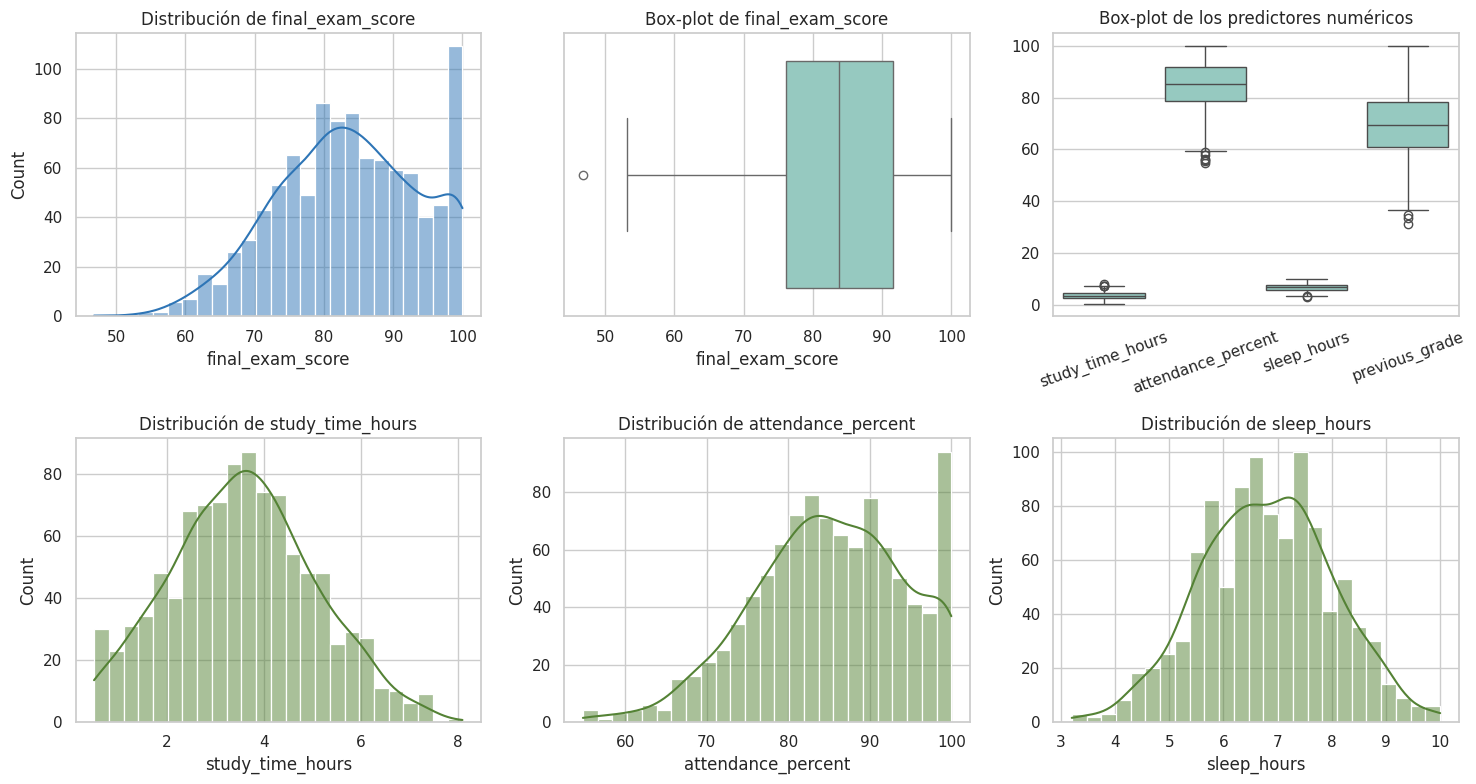

,final_exam_score,study_time_hours,attendance_percent,sleep_hours,previous_grade
count,1000.00,1000.00,1000.00,1000.0,1000.00
mean,83.54,3.57,85.09,6.8,69.74
std,10.34,1.48,9.27,1.2,12.61
min,46.80,0.50,54.80,3.2,31.30
25%,76.07,2.60,78.80,5.9,61.00
50%,83.80,3.60,85.20,6.8,69.60
75%,91.52,4.50,91.90,7.6,78.40
max,100.00,8.10,100.00,10.0,100.00


In [34]:
objetivo = "final_exam_score"
num_pred = ["study_time_hours", "attendance_percent", "sleep_hours", "previous_grade"]

fig, ejes = plt.subplots(2, 3, figsize=(15, 8))
sns.histplot(est[objetivo], bins=25, kde=True, ax=ejes[0, 0], color="#2E75B6")
ejes[0, 0].set_title(f"Distribución de {objetivo}")
sns.boxplot(x=est[objetivo], ax=ejes[0, 1], color="#8ED1C6")
ejes[0, 1].set_title(f"Box-plot de {objetivo}")
sns.boxplot(data=est[num_pred], ax=ejes[0, 2], color="#8ED1C6")
ejes[0, 2].set_title("Box-plot de los predictores numéricos")
ejes[0, 2].tick_params(axis="x", rotation=20)
for i, v in enumerate(num_pred[:3]):
    sns.histplot(est[v], bins=25, kde=True, ax=ejes[1, i], color="#548235")
    ejes[1, i].set_title(f"Distribución de {v}")
plt.tight_layout()
plt.show()

est[[objetivo] + num_pred].describe().round(2)

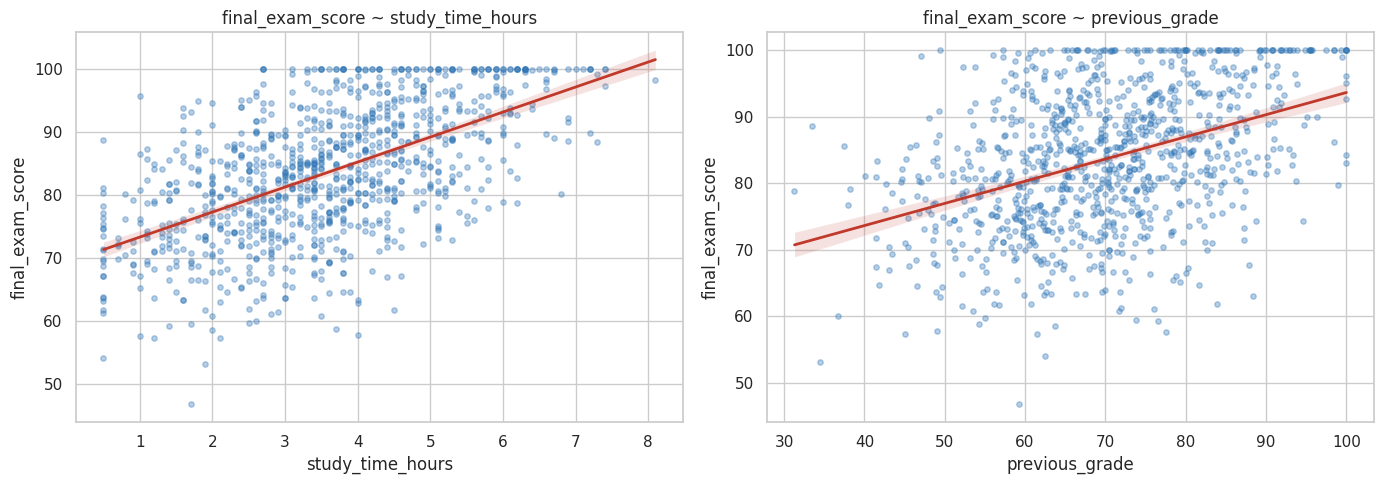

In [35]:
fig, ejes = plt.subplots(1, 2, figsize=(14, 5))
for ax, v in zip(ejes, ["study_time_hours", "previous_grade"]):
    sns.regplot(data=est, x=v, y=objetivo, ax=ax,
                scatter_kws={"alpha": 0.35, "s": 15, "color": "#2E75B6"}, line_kws={"color": "#C0392B", "lw": 2})
    ax.set_title(f"{objetivo} ~ {v}")
plt.tight_layout()
plt.show()

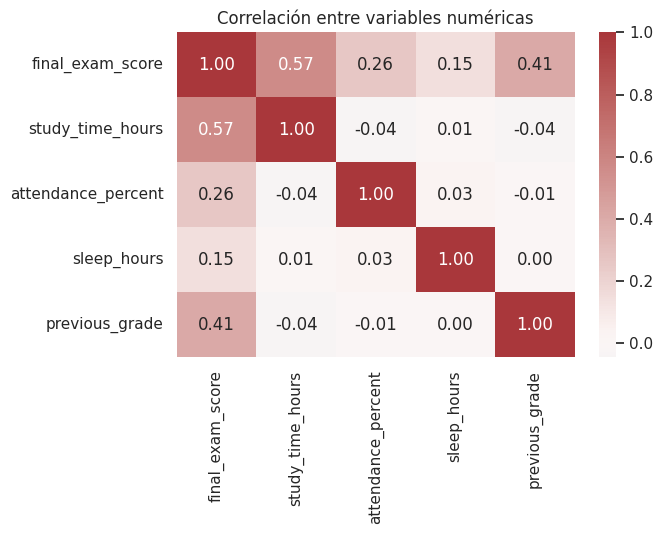

study_time_hours      0.568
previous_grade        0.406
attendance_percent    0.262
sleep_hours           0.148
Name: final_exam_score, dtype: float64


In [36]:
plt.figure(figsize=(7, 5.5))
sns.heatmap(est[[objetivo] + num_pred].corr(), annot=True, fmt=".2f", cmap="vlag", center=0)
plt.title("Correlación entre variables numéricas")
plt.tight_layout()
plt.show()

print(est[[objetivo] + num_pred].corr()[objetivo].drop(objetivo).round(3).sort_values(ascending=False))

**Interpretación del EDA**

La nota final se concentra entre aproximadamente 76 y 92 puntos (mediana 83,8) y tiene una cola hacia las notas bajas. Además hay una **acumulación en 100**: 78 estudiantes (7,8 %) tienen exactamente 100, lo que sugiere que la escala tiene un tope y que las notas se "cortan" ahí.

En el gráfico de correlaciones, las variables más asociadas a la nota final son **`study_time_hours` (r = 0,57)** y **`previous_grade` (r = 0,41)**, seguidas de `attendance_percent` (0,26) y `sleep_hours` (0,15). Además, los predictores numéricos casi no se correlacionan entre sí (la correlación más alta entre ellos es 0,04). Por eso las horas de estudio y la nota previa serán las variables de mayor importancia en el modelo. En los gráficos de regresión se ve una tendencia creciente en ambas.

## 3.2 Selección de predictores y data leakage

**Pregunta de control** aplicada a cada variable: ¿existiría antes de conocer la nota del examen final?

| Variable | Decisión | Motivo |
|---|---|---|
| `final_grade` | **Descarto** | Es la nota en letra (A–F) y se deriva de `final_exam_score`: es la variable objetivo expresada de otra forma. Incluirla sería data leakage. |
| `student_id` | **Descarto** | Es un identificador sin valor predictivo. |
| `previous_grade` | Mantengo | La nota previa existe antes del examen final. |
| `study_time_hours`, `attendance_percent`, `sleep_hours` | Mantengo | Son hábitos y condiciones previas al examen. |
| `gender`, `internet_access`, `extracurricular_activities`, `part_time_job`, `parental_education` | Mantengo | Son características del estudiante conocidas de antemano. Las de texto se convierten a columnas 0/1. |

In [37]:
descartar = ["student_id", "final_grade", objetivo]
X_raw = est.drop(columns=descartar)

# Las variables de texto se convierten a columnas 0/1 (la primera categoría de cada una queda como referencia)
X_all = pd.get_dummies(X_raw, drop_first=True, dtype=float)
y_est = est[objetivo]

print("Predictores del modelo:")
print(X_all.columns.tolist())

Predictores del modelo:
['study_time_hours', 'attendance_percent', 'sleep_hours', 'previous_grade', 'gender_Male', 'parental_education_Desconocido', 'parental_education_High School', 'parental_education_Masters', 'parental_education_PhD', 'internet_access_Yes', 'extracurricular_activities_Yes', 'part_time_job_Yes']


## 3.3 Multicolinealidad

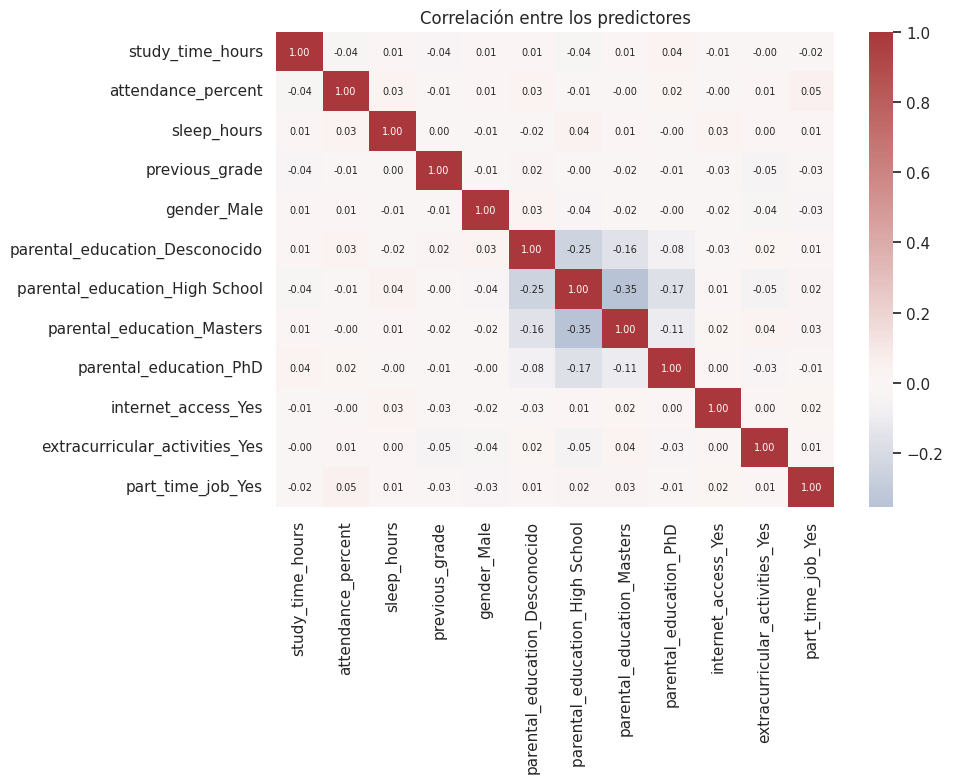

,variable,VIF
0,parental_education_High School,1.40
1,parental_education_Masters,1.31
2,parental_education_Desconocido,1.20
3,parental_education_PhD,1.11
4,extracurricular_activities_Yes,1.01
5,attendance_percent,1.01
6,part_time_job_Yes,1.01
7,study_time_hours,1.01
8,previous_grade,1.01
9,gender_Male,1.01


In [38]:
plt.figure(figsize=(10, 8))
sns.heatmap(X_all.corr(), annot=True, fmt=".2f", cmap="vlag", center=0, annot_kws={"size": 7})
plt.title("Correlación entre los predictores")
plt.tight_layout()
plt.show()

calcular_vif(X_all).round(2)

**Decisión sobre multicolinealidad**

Los predictores casi no se correlacionan entre sí, y el **VIF máximo es 1,40** (en `parental_education_High School`), muy por debajo de la alerta de 5–10. Los VIF más altos corresponden a las columnas de `parental_education`, algo esperable porque son categorías de una misma variable y por construcción se relacionan un poco entre sí. **Decisión: mantengo todos los predictores**, y sus coeficientes se pueden interpretar sin riesgo de inestabilidad por multicolinealidad.

## 3.4 Modelo, métricas y residuos
Partición 80/20 con `random_state=42`.

In [39]:
X_tr3, X_te3, y_tr3, y_te3 = train_test_split(X_all, y_est, test_size=0.2, random_state=42)

modelo_est = LinearRegression().fit(X_tr3, y_tr3)
pred_tr3 = modelo_est.predict(X_tr3)
pred_te3 = modelo_est.predict(X_te3)

tabla_met3 = pd.DataFrame({
    "Entrenamiento": metricas(y_tr3, pred_tr3),
    "Prueba": metricas(y_te3, pred_te3),
}).T
print("Métricas (final_exam_score en puntos):")
display(tabla_met3.round(4))

coefs3 = pd.DataFrame({"predictor": X_all.columns, "coeficiente": modelo_est.coef_}) \
           .sort_values("coeficiente", key=abs, ascending=False)
print(f"Intercepto: {modelo_est.intercept_:.3f}")
coefs3.round(4)

Métricas (final_exam_score en puntos):


,R2,MAE,RMSE
Entrenamiento,0.6744,4.6909,5.8781
Prueba,0.6174,4.9797,6.4172


Intercepto: 4.575


,predictor,coeficiente
9,internet_access_Yes,5.9968
0,study_time_hours,4.1193
11,part_time_job_Yes,-3.5876
8,parental_education_PhD,1.0676
2,sleep_hours,1.0111
10,extracurricular_activities_Yes,0.8376
7,parental_education_Masters,0.8084
5,parental_education_Desconocido,-0.5426
3,previous_grade,0.3511
1,attendance_percent,0.3342


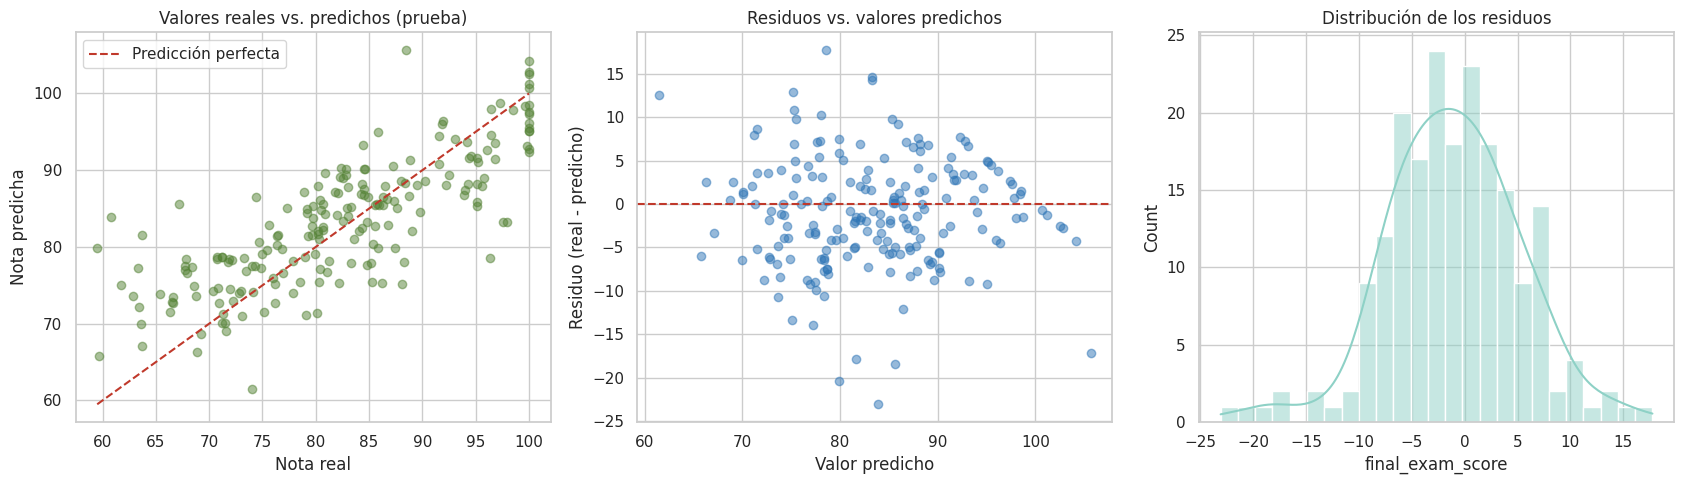

In [40]:
resid3 = y_te3 - pred_te3

fig, ejes = plt.subplots(1, 3, figsize=(17, 5))

ejes[0].scatter(y_te3, pred_te3, alpha=0.5, color="#548235")
lim = [y_te3.min(), y_te3.max()]
ejes[0].plot(lim, lim, color="#C0392B", ls="--", label="Predicción perfecta")
ejes[0].set_xlabel("Nota real")
ejes[0].set_ylabel("Nota predicha")
ejes[0].set_title("Valores reales vs. predichos (prueba)")
ejes[0].legend()

ejes[1].scatter(pred_te3, resid3, alpha=0.5, color="#2E75B6")
ejes[1].axhline(0, color="#C0392B", ls="--")
ejes[1].set_xlabel("Valor predicho")
ejes[1].set_ylabel("Residuo (real - predicho)")
ejes[1].set_title("Residuos vs. valores predichos")

sns.histplot(resid3, bins=25, kde=True, ax=ejes[2], color="#8ED1C6")
ejes[2].set_title("Distribución de los residuos")
plt.tight_layout()
plt.show()

**Interpretación de métricas y coeficientes**

| | R² | MAE | RMSE |
|---|---|---|---|
| Entrenamiento | 0,674 | 4,69 | 5,88 |
| Prueba | 0,617 | 4,98 | 6,42 |

El modelo explica cerca del **62 %** de la variación de la nota en datos que no vio, y en promedio se equivoca en unos **5 puntos** (MAE), frente a una desviación estándar de la nota de 10,3.

**Coeficientes (con unidades; efecto manteniendo constantes las demás variables):**

- **`study_time_hours` = +4,12:** cada hora adicional de estudio se asocia con unos 4,1 puntos más en el examen.
- **`previous_grade` = +0,35:** cada punto más en la nota previa se asocia con 0,35 puntos más en el examen.
- **`part_time_job_Yes` = −3,59:** los estudiantes con trabajo de medio tiempo obtienen en promedio 3,6 puntos menos que los que no trabajan.
- **`internet_access_Yes` = +6,00:** tener acceso a internet se asocia con unos 6 puntos más.

**Cautelas:** no se pueden comparar directamente los tamaños de coeficientes de variables con unidades distintas (el de `internet_access` es un salto de 0 a 1, el de `study_time_hours` es por cada hora). Además, son asociaciones, no causas, y este dataset es sintético (generado con una fórmula más ruido aleatorio).

**Gráficos:** en reales contra predichos los puntos siguen la diagonal con dispersión moderada. En los residuos no se ve una curva ni un embudo, y su histograma tiene forma de campana, con una pequeña cola hacia valores negativos.

## 3.5 Heterogeneidad
Calculo las métricas del conjunto de prueba por subgrupo, para ver si el error promedio esconde diferencias.

In [41]:
def metricas_por_grupo(columna):
    g_te = est.loc[X_te3.index, columna]
    filas = []
    for g in sorted(g_te.unique()):
        m = (g_te == g).values
        r = metricas(y_te3[m], pred_te3[m])
        filas.append({columna: g, "n_prueba": int(m.sum()), **r,
                      "sesgo_medio": float((y_te3[m] - pred_te3[m]).mean())})
    return pd.DataFrame(filas).set_index(columna)

for col in ["part_time_job", "gender", "internet_access", "parental_education"]:
    print(f"\n=== Métricas por {col} (conjunto de prueba) ===")
    display(metricas_por_grupo(col).round(3))


=== Métricas por part_time_job (conjunto de prueba) ===


,n_prueba,R2,MAE,RMSE,sesgo_medio
part_time_job,,,,,
No,146,0.640,4.828,6.286,-1.551
Yes,54,0.548,5.389,6.758,0.188



=== Métricas por gender (conjunto de prueba) ===


,n_prueba,R2,MAE,RMSE,sesgo_medio
gender,,,,,
Female,105,0.581,5.413,6.698,-0.899
Male,95,0.654,4.501,6.092,-1.284



=== Métricas por internet_access (conjunto de prueba) ===


,n_prueba,R2,MAE,RMSE,sesgo_medio
internet_access,,,,,
No,33,0.685,5.631,6.486,1.192
Yes,167,0.594,4.851,6.404,-1.531



=== Métricas por parental_education (conjunto de prueba) ===


,n_prueba,R2,MAE,RMSE,sesgo_medio
parental_education,,,,,
Bachelors,56,0.500,4.637,6.438,-0.768
Desconocido,16,0.780,4.593,5.653,-0.820
High School,80,0.606,5.548,6.890,-1.000
Masters,40,0.677,4.486,5.892,-1.270
PhD,8,0.347,4.930,5.218,-3.672


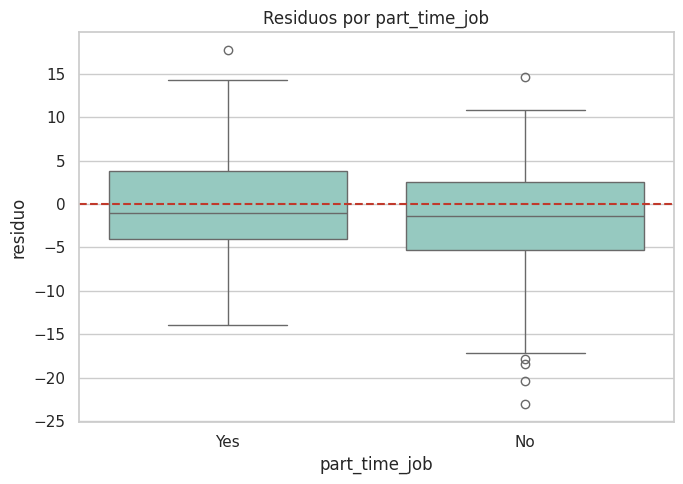

In [42]:
seg = "part_time_job"
res_seg = resid3.to_frame("residuo")
res_seg[seg] = est.loc[X_te3.index, seg]

plt.figure(figsize=(7, 5))
sns.boxplot(data=res_seg, x=seg, y="residuo", color="#8ED1C6")
plt.axhline(0, color="#C0392B", ls="--")
plt.title(f"Residuos por {seg}")
plt.tight_layout()
plt.show()

**Comentario sobre heterogeneidad**

Segmenté por `part_time_job`, `gender`, `internet_access` y `parental_education`. Las diferencias son **moderadas**: por ejemplo, el MAE es 4,8 para quienes no trabajan y 5,4 para quienes sí (R² de 0,64 y 0,55), y 4,5 para hombres frente a 5,4 para mujeres. No hay un subgrupo donde el modelo falle de forma extrema.

**Precaución:** el conjunto de prueba tiene solo 200 estudiantes, así que algunos subgrupos son muy pequeños (por ejemplo, solo 8 con `PhD` y 16 con `Desconocido`) y sus métricas no son confiables. Parte de las diferencias entre grupos puede ser ruido. Para confirmarlo habría que repetir el análisis con validación cruzada.

## 3.6 Preguntas de cierre

**(a) Interpretación de un coeficiente.** El coeficiente de `study_time_hours` es **+4,12**: manteniendo constantes las demás variables, cada hora adicional de estudio se asocia con unos **4,1 puntos más** en el examen final (en puntos de la escala de 0 a 100).

**(b) Error de entrenamiento y de prueba.** El RMSE fue 5,88 en entrenamiento y 6,42 en prueba, y el R² bajó de 0,674 a 0,617. El error es algo mayor en datos nuevos, lo que es normal: el modelo se ajusta un poco mejor a los datos con que se entrenó. La brecha es **pequeña**, así que no hay un sobreajuste importante y el modelo generaliza razonablemente.

**(c) Supuesto de la regresión lineal.** Los supuestos de **homocedasticidad** (la dispersión de los residuos es similar en todo el rango de valores predichos) y **normalidad** de los residuos (histograma en forma de campana) se cumplen razonablemente, sin curvas ni embudos en el gráfico de residuos. En cambio, el supuesto de **linealidad sin límites** se incumple en el extremo alto: la nota tiene un tope de 100, que alcanzan 78 estudiantes (7,8 %), pero la recta no conoce ese límite y **predijo notas sobre 100 en 6 de los 200 casos de prueba (hasta 105,7)**, lo que es imposible. Esto se ve en el gráfico de reales contra predichos, donde las notas reales se apilan en 100 mientras las predicciones siguen subiendo.

---
## Declaración de uso de herramientas
Utilicé Claude (Anthropic) como apoyo para estructurar el notebook, escribir el código base y redactar borradores de las explicaciones, y para resolver errores (por ejemplo, el dataset de la pauta que ya no estaba disponible). Ejecuté yo mismo el notebook, tomé las decisiones sobre variables y umbrales, y revisé las interpretaciones contra mis propios resultados.